# 06_05 — BCM_GUN self-correlation in time

How much does the charge of shot *t* depend on the charge of the previous shots?

1. **Autocorrelation:** r between `BCM_GUN[t]` and `BCM_GUN[t − n]`, for n = 1 … 10
   - **overall** — raw values, includes the slow drift over the run
   - **shot-to-shot** — 51-shot rolling mean removed first, so only the fast part is left
2. **Prediction from the window** `BCM_GUN[t − n : t]`: a linear model (least squares) that predicts `BCM_GUN[t]`
   from the last *n* shots, for n = 1 … 10. Trained on the first 70% of the run, scored on the last 30% (R²),
   so it never sees the future.

Noise level for ~2100 shots: |r| ≲ 0.07.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
files = sorted(DATA_DIR.glob("chunk_*.h5"))

N_MAX = 10
TRAIN_FRACTION = 0.7
SERIES = ["#2a78d6", "#eb6834"]  # overall, shot-to-shot
MUTED = "#8a8985"

charge = pd.Series(np.concatenate([h5py.File(path, "r")["BCM_GUN"][:] for path in files]), name="BCM_GUN")
print(f"{len(charge)} shots, mean {charge.mean():.3f}, std {charge.std():.3f}")

6100 shots, mean 4.865, std 3.220


## 1. Autocorrelation

In [2]:
def detrend(x, k=51):
    return x - x.rolling(k, center=True, min_periods=1).mean()


N = np.arange(1, N_MAX + 1)
acf = pd.DataFrame({
    "overall": [charge.autocorr(n) for n in N],
    "shot-to-shot": [detrend(charge).autocorr(n) for n in N],
}, index=pd.Index(N, name="n"))
acf.round(3).T

n,1,2,3,4,5,6,7,8,9,10
overall,0.980,0.973,0.967,0.961,0.955,0.949,0.944,0.938,0.933,0.928
shot-to-shot,0.671,0.569,0.475,0.386,0.304,0.224,0.161,0.098,0.042,-0.008


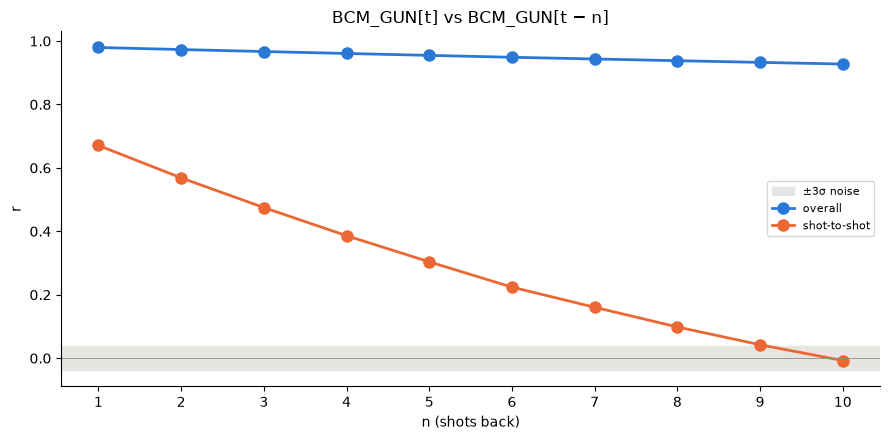

In [3]:
noise = 3 / np.sqrt(len(charge))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axhspan(-noise, noise, color="#e6e5e1", label="±3σ noise")
for color, col in zip(SERIES, acf.columns):
    ax.plot(N, acf[col], "o-", color=color, lw=2, ms=8, label=col)
ax.axhline(0, color=MUTED, lw=0.6)
ax.set(xticks=N, xlabel="n (shots back)", ylabel="r", title="BCM_GUN[t] vs BCM_GUN[t − n]")
ax.legend(fontsize=8)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()

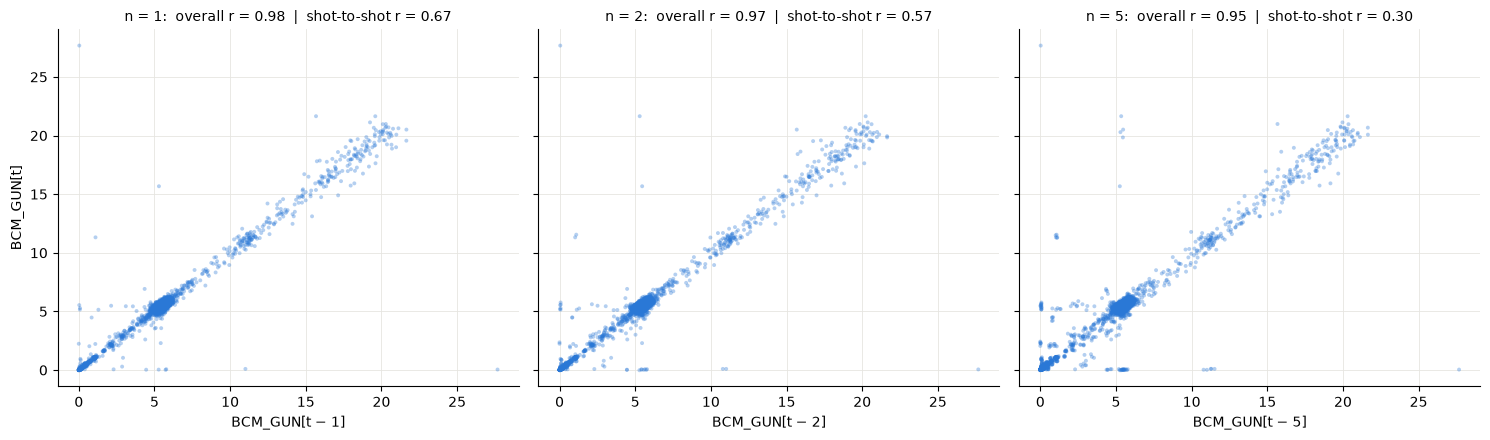

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, n in zip(axes, [1, 2, 5]):
    ax.scatter(charge.shift(n), charge, s=8, color=SERIES[0], alpha=0.35, edgecolors="none")
    ax.set(xlabel=f"BCM_GUN[t − {n}]", title=f"n = {n}:  overall r = {acf.loc[n, 'overall']:.2f}  |  "
                                             f"shot-to-shot r = {acf.loc[n, 'shot-to-shot']:.2f}")
    ax.title.set_fontsize(10)
    ax.grid(color="#e6e5e1", lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[0].set_ylabel("BCM_GUN[t]")
fig.tight_layout()

## 2. Predicting BCM_GUN[t] from the window BCM_GUN[t − n : t]

Linear model `BCM_GUN[t] ≈ a₀ + a₁·BCM_GUN[t−1] + … + aₙ·BCM_GUN[t−n]`, fitted on the first 70% of the run.

R² on the last 30%: 1 = perfect, 0 = no better than always predicting the training mean (negative = worse).
For reference, two simple predictors are scored on the same test shots: *same as previous shot* and *mean of the last n shots*.

In [5]:
def r2(y, pred):
    return 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)


window = pd.concat({n: charge.shift(n) for n in N}, axis=1).iloc[N_MAX:]  # column n = BCM_GUN[t - n]
target = charge.iloc[N_MAX:]
split = int(TRAIN_FRACTION * len(target))

rows = []
for n in N:
    X = np.column_stack([np.ones(len(target)), window[list(range(1, n + 1))]])
    coef, *_ = np.linalg.lstsq(X[:split], target.iloc[:split], rcond=None)
    rows.append({
        "n": n,
        "linear model": r2(target.iloc[split:], X[split:] @ coef),
        "mean of last n": r2(target.iloc[split:], window.iloc[split:, :n].mean(axis=1)),
        "weights a1…an": np.round(coef[1:], 2),
    })
pred = pd.DataFrame(rows).set_index("n")
print(f"R² on the last {len(target) - split} shots; 'same as previous shot' gives R² = "
      f"{r2(target.iloc[split:], window.iloc[split:, 0]):.3f}")
pred.round(3)

R² on the last 1827 shots; 'same as previous shot' gives R² = 0.962


,linear model,mean of last n,weights a1…an
n,,,
1,0.955,0.962,[0.9]
2,0.960,0.966,"[0.75, 0.17]"
3,0.961,0.965,"[0.75, 0.14, 0.03]"
4,0.960,0.963,"[0.75, 0.15, 0.06, -0.04]"
5,0.961,0.960,"[0.75, 0.15, 0.05, -0.07, 0.05]"
6,0.961,0.957,"[0.75, 0.15, 0.05, -0.08, 0.03, 0.02]"
7,0.962,0.954,"[0.75, 0.15, 0.05, -0.08, 0.03, -0.01, 0.04]"
8,0.962,0.951,"[0.75, 0.15, 0.05, -0.08, 0.03, -0.01, 0.02, 0..."
9,0.962,0.948,"[0.75, 0.15, 0.05, -0.08, 0.03, -0.01, 0.02, 0..."


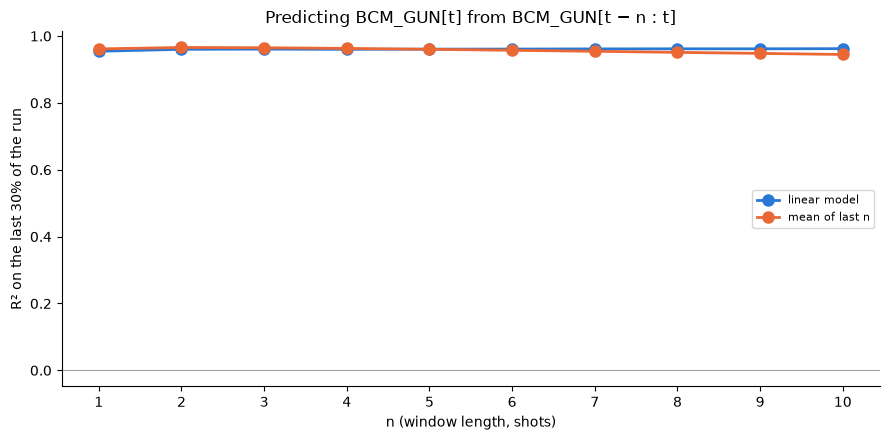

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for color, col in zip(SERIES, ["linear model", "mean of last n"]):
    ax.plot(N, pred[col], "o-", color=color, lw=2, ms=8, label=col)
ax.axhline(0, color=MUTED, lw=0.6)
ax.set(xticks=N, xlabel="n (window length, shots)", ylabel="R² on the last 30% of the run",
       title="Predicting BCM_GUN[t] from BCM_GUN[t − n : t]")
ax.legend(fontsize=8)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()

## 3. Predicting BCM_GUN[t] from a single past shot BCM_GUN[t − n]

Same train/test split, but each model uses **only one** past shot: `BCM_GUN[t] ≈ a₀ + a·BCM_GUN[t − n]`.
The window model from section 2 is shown again for comparison.

n                     1      2      3      4      5      6      7      8   \
single shot t − n  0.955  0.932  0.906  0.873  0.844  0.812  0.785  0.758   
weight a           0.902  0.845  0.795  0.740  0.700  0.661  0.630  0.603   

n                     9      10  
single shot t − n  0.729  0.713  
weight a           0.574  0.563  


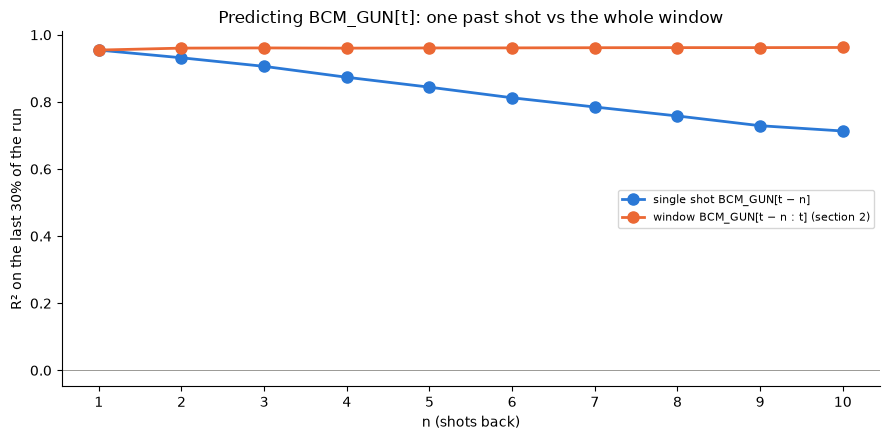

In [7]:
single = []
for n in N:
    X = np.column_stack([np.ones(len(target)), window[n]])
    coef, *_ = np.linalg.lstsq(X[:split], target.iloc[:split], rcond=None)
    single.append({"n": n, "single shot t − n": r2(target.iloc[split:], X[split:] @ coef), "weight a": coef[1]})
single = pd.DataFrame(single).set_index("n")
print(single.round(3).T)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(N, single["single shot t − n"], "o-", color=SERIES[0], lw=2, ms=8, label="single shot BCM_GUN[t − n]")
ax.plot(N, pred["linear model"], "o-", color=SERIES[1], lw=2, ms=8, label="window BCM_GUN[t − n : t] (section 2)")
ax.axhline(0, color=MUTED, lw=0.6)
ax.set(xticks=N, xlabel="n (shots back)", ylabel="R² on the last 30% of the run",
       title="Predicting BCM_GUN[t]: one past shot vs the whole window")
ax.legend(fontsize=8)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()